In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\acer.DESKTOP-1VQGBE7\OneDrive\Desktop\internship\train.csv", dtype = {"StateHoliday": "string"})
df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [9]:
df.types

Store                     int64
DayOfWeek                 int64
Date                     object
Sales                     int64
Customers                 int64
Open                      int64
Promo                     int64
StateHoliday     string[python]
SchoolHoliday             int64
dtype: object

In [11]:
df.shape

(1017209, 9)

In [15]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   Store          1017209 non-null  int64 
 1   DayOfWeek      1017209 non-null  int64 
 2   Date           1017209 non-null  object
 3   Sales          1017209 non-null  int64 
 4   Customers      1017209 non-null  int64 
 5   Open           1017209 non-null  int64 
 6   Promo          1017209 non-null  int64 
 7   StateHoliday   1017209 non-null  string
 8   SchoolHoliday  1017209 non-null  int64 
dtypes: int64(7), object(1), string(1)
memory usage: 69.8+ MB


# Data Preparation

In [45]:
df = df.drop_duplicates()

In [47]:
df.isnull().sum()

Store            0
DayOfWeek        0
Date             0
Sales            0
Customers        0
Open             0
Promo            0
StateHoliday     0
SchoolHoliday    0
Year             0
Month            0
Day              0
WeekOfYear       0
dtype: int64

In [49]:
df['Date'] = pd.to_datetime(df['Date'])

In [51]:
df = df.sort_values("Date")
df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear
1017208,1115,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017205,1112,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017204,1111,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017203,1110,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017202,1109,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,5,4,2015-07-31,4822,559,1,1,0,1,2015,7,31,31
3,4,4,2015-07-31,13995,1498,1,1,0,1,2015,7,31,31
2,3,4,2015-07-31,8314,821,1,1,0,1,2015,7,31,31
7,8,4,2015-07-31,8492,833,1,1,0,1,2015,7,31,31


In [53]:
df.duplicated(subset=["Store", "Date"]).sum()

0

In [55]:
print("Sales <= 0:", (df["Sales"] <= 0).sum())
print("Customers < 0:", (df["Customers"] < 0).sum())

Sales <= 0: 172871
Customers < 0: 0


In [57]:
df['StateHoliday'].value_counts()

StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: Int64

In [59]:
df['Open'].value_counts()

Open
1    844392
0    172817
Name: count, dtype: int64

In [61]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day
df["WeekOfYear"] = df["Date"].dt.isocalendar().week
df["DayOfWeek"] = df["Date"].dt.dayofweek

In [63]:
df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear
1017208,1115,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017205,1112,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017204,1111,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017203,1110,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1017202,1109,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4,5,4,2015-07-31,4822,559,1,1,0,1,2015,7,31,31
3,4,4,2015-07-31,13995,1498,1,1,0,1,2015,7,31,31
2,3,4,2015-07-31,8314,821,1,1,0,1,2015,7,31,31
7,8,4,2015-07-31,8492,833,1,1,0,1,2015,7,31,31


In [65]:
daily_sales = df.groupby('Date')['Sales'].sum().reset_index()
daily_sales = daily_sales.sort_values('Date')
daily_sales

,Date,Sales
0,2013-01-01,97235
1,2013-01-02,6949829
2,2013-01-03,6347820
3,2013-01-04,6638954
4,2013-01-05,5951593
...,...,...
937,2015-07-27,10707292
938,2015-07-28,9115073
939,2015-07-29,8499962
940,2015-07-30,8798854


In [67]:
daily_data = df.groupby('Date').agg({
    'Sales':'sum',
    'Promo':'mean',
    'Customers':'sum'
})

daily_data

,Sales,Promo,Customers
Date,,,
2013-01-01,97235,0.0,19491
2013-01-02,6949829,0.0,834075
2013-01-03,6347820,0.0,761040
2013-01-04,6638954,0.0,782137
2013-01-05,5951593,0.0,687472
...,...,...,...
2015-07-27,10707292,1.0,970462
2015-07-28,9115073,1.0,876092
2015-07-29,8499962,1.0,828524


In [69]:
daily_data = daily_data.sort_index()

In [31]:
df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,Year,Month,Day,WeekOfYear
1017208,1115,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1016473,379,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1016472,378,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1016471,377,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
1016470,376,1,2013-01-01,0,0,0,0,a,1,2013,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,746,4,2015-07-31,9082,638,1,1,0,1,2015,7,31,31
746,747,4,2015-07-31,10708,826,1,1,0,1,2015,7,31,31
747,748,4,2015-07-31,7481,578,1,1,0,1,2015,7,31,31
741,742,4,2015-07-31,10460,1016,1,1,0,1,2015,7,31,31


# Exploratory Data Analysis(EDA)

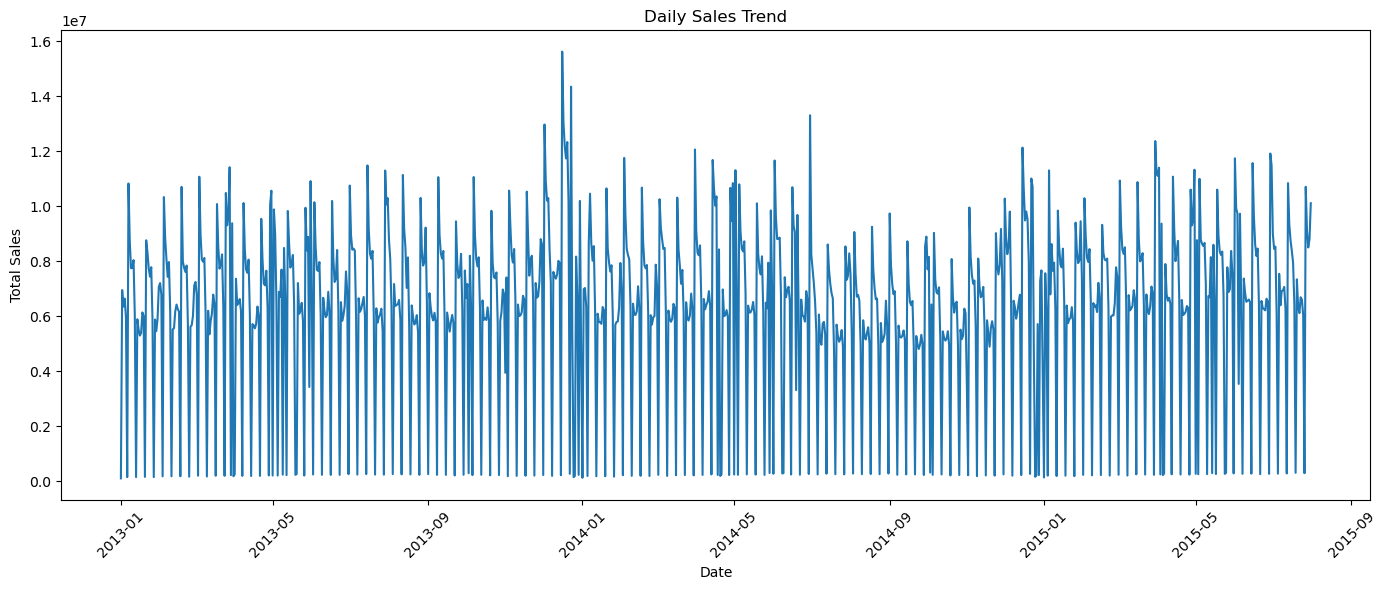

In [81]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_data.index,
    daily_data["Sales"]
)

plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

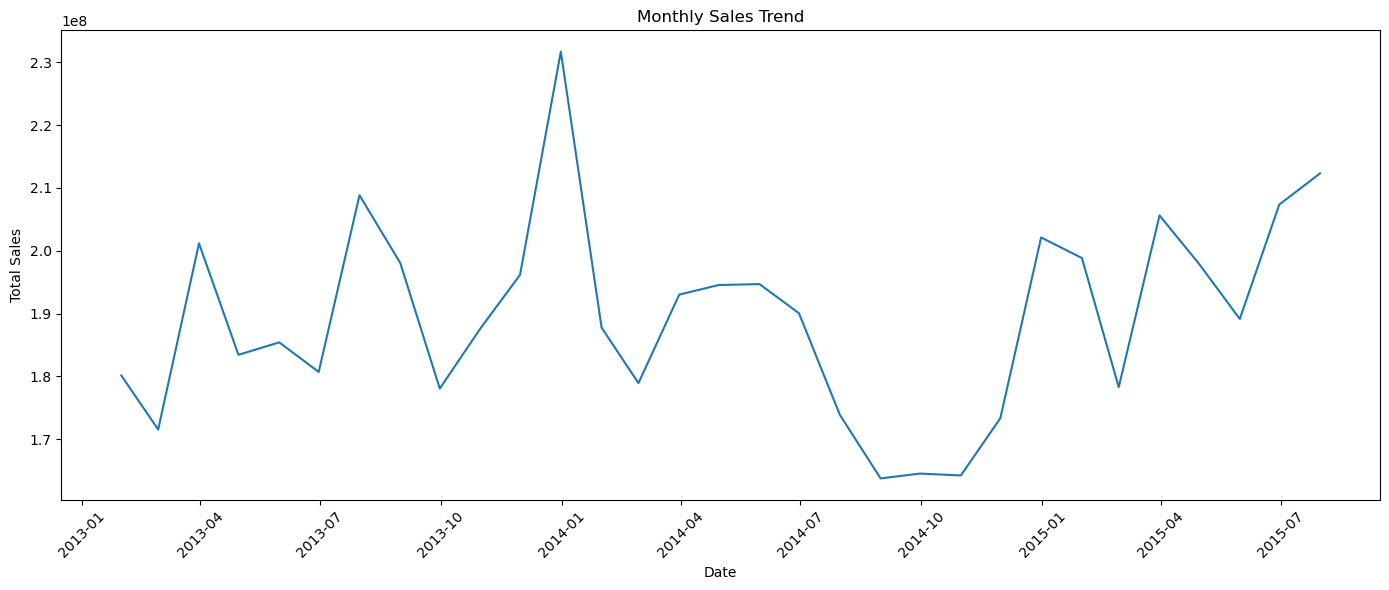

In [83]:
monthly_sales = daily_data["Sales"].resample("ME").sum()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values
)

plt.title("Monthly Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

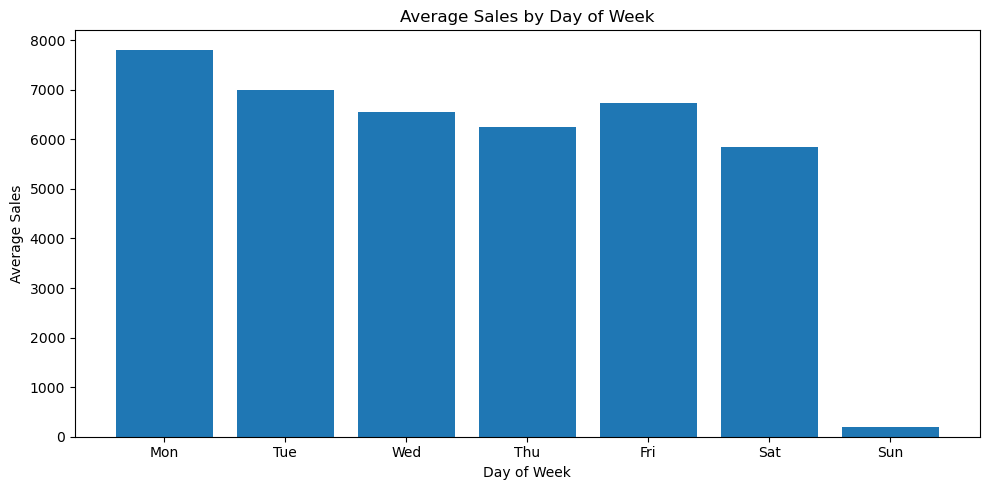

In [85]:
day_sales = df.groupby("DayOfWeek")["Sales"].mean()

plt.figure(figsize=(10, 5))

plt.bar(
    day_sales.index,
    day_sales.values
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")

plt.xticks(
    range(0, 7),
    ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
)

plt.tight_layout()
plt.show()

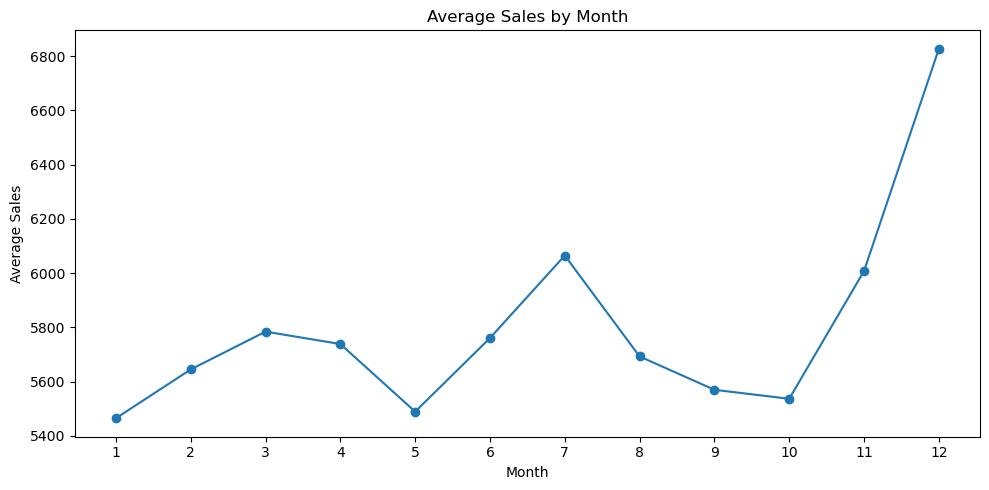

In [87]:
month_sales = df.groupby("Month")["Sales"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    month_sales.index,
    month_sales.values,
    marker="o"
)

plt.title("Average Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Sales")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

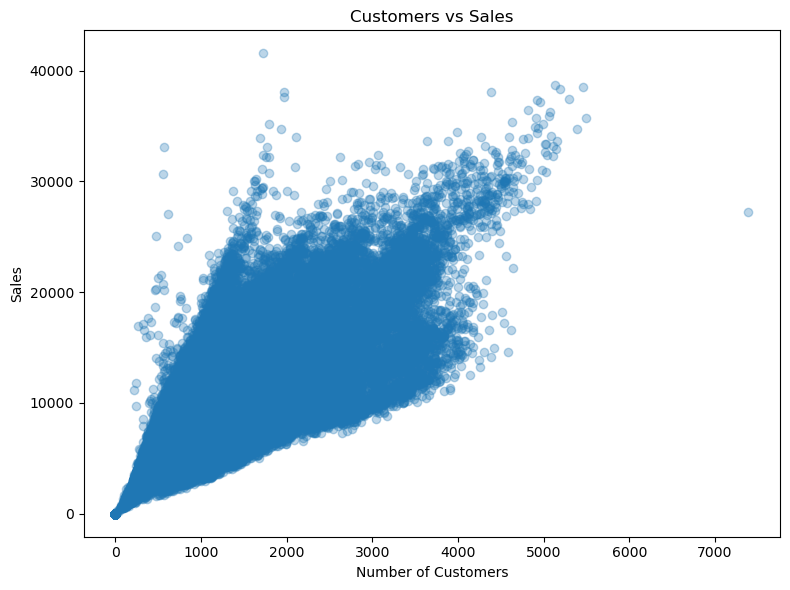

In [89]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Customers"],
    df["Sales"],
    alpha=0.3
)

plt.title("Customers vs Sales")
plt.xlabel("Number of Customers")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()


Promotion Distribution:
Promo
0    629129
1    388080
Name: count, dtype: int64


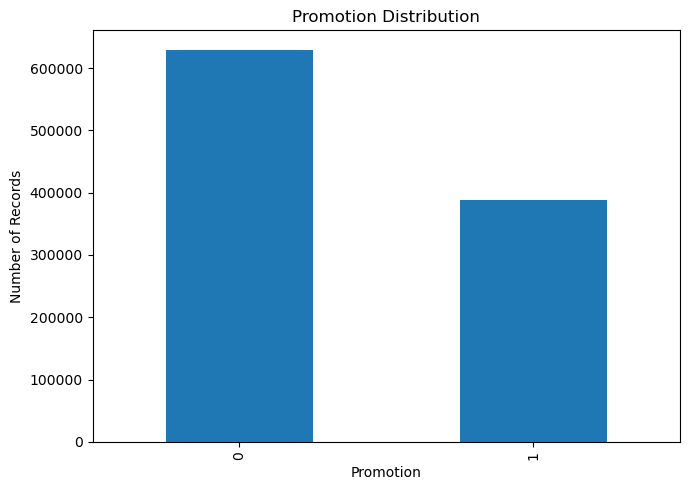

In [91]:
print("\nPromotion Distribution:")
print(df["Promo"].value_counts())

plt.figure(figsize=(7, 5))

df["Promo"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Promotion Distribution")
plt.xlabel("Promotion")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

# Modeling

In [98]:
model_data = daily_data.copy()

model_data.index = pd.to_datetime(model_data.index)

model_data = model_data.sort_index()

print(model_data.head())
print(model_data.info())


full_dates = pd.date_range(
    start=model_data.index.min(),
    end=model_data.index.max(),
    freq="D"
)

missing_dates = full_dates.difference(model_data.index)

print("\nNumber of missing dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("Missing dates:")
    print(missing_dates)


model_data = model_data.asfreq("D")

print("\nMissing values after setting daily frequency:")
print(model_data.isnull().sum())

              Sales  Promo  Customers
Date                                 
2013-01-01    97235    0.0      19491
2013-01-02  6949829    0.0     834075
2013-01-03  6347820    0.0     761040
2013-01-04  6638954    0.0     782137
2013-01-05  5951593    0.0     687472
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 942 entries, 2013-01-01 to 2015-07-31
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Sales      942 non-null    int64  
 1   Promo      942 non-null    float64
 2   Customers  942 non-null    int64  
dtypes: float64(1), int64(2)
memory usage: 29.4 KB
None

Number of missing dates: 0

Missing values after setting daily frequency:
Sales        0
Promo        0
Customers    0
dtype: int64


# Train/ Test Split

In [103]:
train_size = int(len(model_data) * 0.8)

train = model_data.iloc[:train_size]
test = model_data.iloc[train_size:]

print("Training Data:")
print(train.shape)

print("\nTesting Data:")
print(test.shape)

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

Training Data:
(753, 3)

Testing Data:
(189, 3)

Training Period:
2013-01-01 00:00:00 to 2015-01-23 00:00:00

Testing Period:
2015-01-24 00:00:00 to 2015-07-31 00:00:00


# SARIMAX Model

In [108]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(
    train["Sales"],
    exog=train[["Promo", "Customers"]],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

print(model_fit.summary())

                                     SARIMAX Results                                     
Dep. Variable:                             Sales   No. Observations:                  753
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood              -10399.807
Date:                           Wed, 07 Oct 2026   AIC                          20813.613
Time:                                   18:31:58   BIC                          20845.822
Sample:                               01-01-2013   HQIC                         20826.035
                                    - 01-23-2015                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Promo       1.115e+06   1.06e+05     10.555      0.000    9.08e+05    1.32e+06
Customers      9.4674      0.102     93.186

# Forecast Test Data

In [110]:
forecast_result = model_fit.get_forecast(
    steps=len(test),
    exog=test[["Promo", "Customers"]]
)

forecast = forecast_result.predicted_mean

confidence_interval = forecast_result.conf_int()

print("Forecasted Sales:")
print(forecast.head())

Forecasted Sales:
2015-01-24    5.567582e+06
2015-01-25   -1.611539e+05
2015-01-26    9.447504e+06
2015-01-27    8.356177e+06
2015-01-28    7.842349e+06
Freq: D, Name: predicted_mean, dtype: float64


# Actual vs Forecasted data

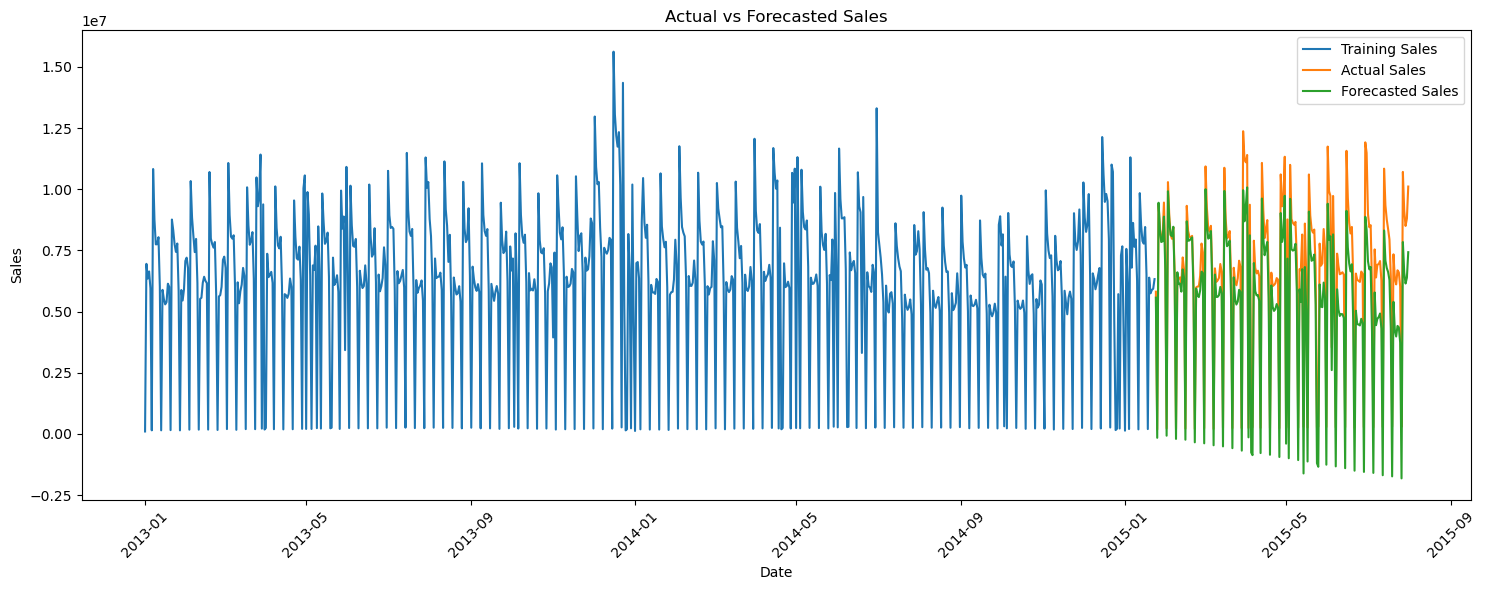

In [113]:
# =========================================================
# ACTUAL VS FORECASTED SALES
# =========================================================

plt.figure(figsize=(15, 6))

plt.plot(
    train.index,
    train["Sales"],
    label="Training Sales"
)

plt.plot(
    test.index,
    test["Sales"],
    label="Actual Sales"
)

plt.plot(
    test.index,
    forecast,
    label="Forecasted Sales"
)

plt.title("Actual vs Forecasted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Model Evaluation

In [117]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = test["Sales"]
predicted = forecast

# MAE
mae = mean_absolute_error(
    actual,
    predicted
)

# RMSE
rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

# MAPE
mape = np.mean(
    np.abs(
        (actual - predicted) / actual
    )
) * 100


print("====================================")
print("       MODEL EVALUATION")
print("====================================")

print(f"MAE  : {mae:,.2f}")
print(f"RMSE : {rmse:,.2f}")
print(f"MAPE : {mape:.2f}%")

       MODEL EVALUATION
MAE  : 1,232,816.81
RMSE : 1,425,158.06
MAPE : 90.88%


# Forecast Next 30 days

In [120]:
forecast_days = 30

future_dates = pd.date_range(
    start=model_data.index.max() + pd.Timedelta(days=1),
    periods=forecast_days,
    freq="D"
)

# FUTURE EXTERNAL VARIABLES

recent_customers = model_data["Customers"].tail(30).mean()
recent_promo = model_data["Promo"].tail(30).mean()

future_exog = pd.DataFrame({
    "Promo": [recent_promo] * forecast_days,
    "Customers": [recent_customers] * forecast_days
}, index=future_dates)


print("Future External Variables:")
print(future_exog.head())

Future External Variables:
            Promo  Customers
2015-08-01    0.4   711982.8
2015-08-02    0.4   711982.8
2015-08-03    0.4   711982.8
2015-08-04    0.4   711982.8
2015-08-05    0.4   711982.8
